| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../20_INVESTIGACION/20_3_Diseño_experimental.ipynb) | [⏩](../21_MATEMATICA_MAS_AVANZADA/21_2_Analisis_funcional.ipynb) |

# 21.1 ANÁLISIS REAL PARA SCIENTIFIC MACHINE LEARNING

El análisis real estudia con precisión límites, continuidad, convergencia e integración. En cálculo solemos usar reglas; aquí preguntamos **por qué son válidas**, **bajo qué condiciones** y **cuándo pueden fallar**. Estas preguntas aparecen al refinar una malla, diferenciar una aproximación o afirmar que una secuencia de redes converge.

El cuaderno combina definiciones, demostraciones breves y experimentos Python. Una gráfica finita aporta intuición, pero no prueba una afirmación sobre todos los puntos o todos los índices. Cuando haya un resultado exacto, lo justificaremos matemáticamente y usaremos el código como ilustración.

**Objetivos.** Comprender completitud, distinguir convergencia puntual y uniforme, analizar intercambios de límites y aplicar contracciones. Requisitos: cálculo y sucesiones. Bibliotecas: NumPy, SciPy, Matplotlib y `fractions`.

## 1. Completitud de los reales

Todo conjunto no vacío de reales acotado superiormente tiene un supremo real. Esta propiedad separa $\mathbb R$ de $\mathbb Q$: los racionales $q>0$ con $q^2<2$ tienen una cota, pero su supremo no es racional.

La completitud también puede formularse diciendo que toda sucesión de Cauchy converge en $\mathbb R$. Una sucesión es de Cauchy si sus términos acaban tan cerca entre sí como queramos, aunque todavía no conozcamos el límite. En métodos numéricos esta idea ayuda a justificar existencia de un objeto límite, no solo estabilidad de algunas iteraciones.

## 2. Aproximar √2 con racionales

Empezamos con intervalo $[1,2]$. Su punto medio es racional; si su cuadrado es menor que dos se convierte en extremo izquierdo, y en caso contrario en derecho. Cada paso conserva un intervalo que contiene $\sqrt2$ y reduce longitud a la mitad.

Después de $n$ pasos, la longitud es $2^{-n}$ y el error del punto medio es como máximo $2^{-n-1}$. Esa cota explica convergencia independientemente de cuánto coincida una impresión decimal con la calculadora. Usaremos fracciones exactas para que la comparación de cuadrados no dependa de redondeo flotante.

Último intervalo racional: 11863283/8388608 47453133/33554432


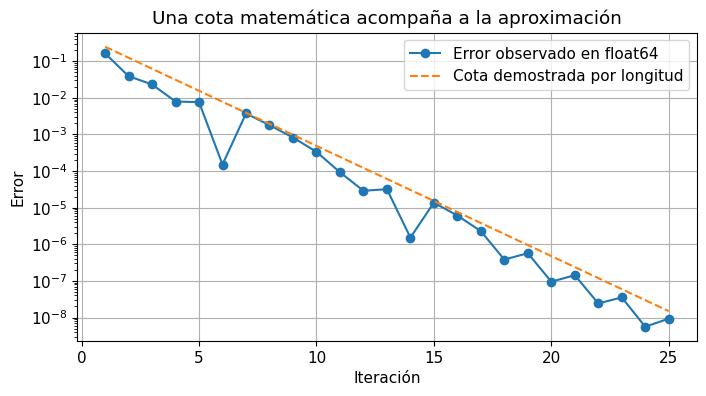

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from scipy.integrate import trapezoid
from scipy.optimize import brentq
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
izq, der = Fraction(1), Fraction(2)
aprox, cotas = [], []
for n in range(1, 26):
    medio = (izq+der)/2
    if medio*medio < 2:
        izq = medio
    else:
        der = medio
    aprox.append(float((izq+der)/2)); cotas.append(float((der-izq)/2))
print("Último intervalo racional:", izq, der)
fig, ax = plt.subplots()
ax.semilogy(np.arange(1, 26), np.abs(np.array(aprox)-np.sqrt(2)), "o-", label="Error observado en float64")
ax.semilogy(np.arange(1, 26), cotas, "--", label="Cota demostrada por longitud")
ax.set(xlabel="Iteración", ylabel="Error", title="Una cota matemática acompaña a la aproximación")
ax.legend(); plt.show()

## 3. Definición ε–N de límite

La afirmación $a_n\to L$ significa: para todo $\varepsilon>0$ existe $N$ tal que $n\ge N$ implica $|a_n-L|<\varepsilon$. El orden de cuantificadores importa: $N$ puede depender de $\varepsilon$, pero no elegimos un $\varepsilon$ favorable después de ver $n$.

Para $a_n=1/n$, dado $\varepsilon>0$ elegimos cualquier entero $N>1/\varepsilon$. Entonces $n\ge N$ implica $1/n\le1/N<\varepsilon$. Esa es una demostración, mientras observar cien valores pequeños solo es una muestra finita.

En una convergencia de malla, el papel de $n$ lo puede representar el número de intervalos. Tener error que baja en cinco mallas es evidencia útil, pero justificar una tasa general requiere regularidad y estabilidad.

## 4. Continuidad ε–δ

$f$ es continua en $a$ si para todo $\varepsilon>0$ existe $\delta>0$ tal que $|x-a|<\delta$ implica $|f(x)-f(a)|<\varepsilon$.

Para $f(x)=x^2$ en $a=2$, si $|x-2|<1$ entonces $|x+2|<5$, así que $|x^2-4|<5|x-2|$. Elegir $\delta=\min(1,\varepsilon/5)$ garantiza la condición. No buscamos el mayor $\delta$ posible: basta uno que funcione.

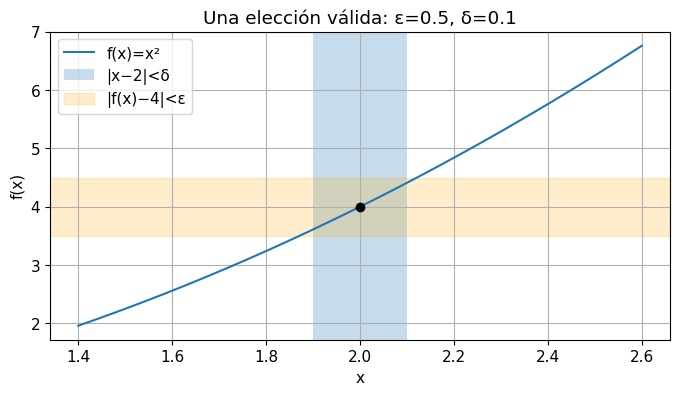

In [2]:
eps, a = 0.5, 2.0
delta = min(1.0, eps/5)
x = np.linspace(1.4, 2.6, 400)
fig, ax = plt.subplots()
ax.plot(x, x*x, label="f(x)=x²")
ax.axvspan(a-delta, a+delta, alpha=0.25, label="|x−2|<δ")
ax.axhspan(a*a-eps, a*a+eps, color="orange", alpha=0.2, label="|f(x)−4|<ε")
ax.plot(a, a*a, "ko")
ax.set(xlabel="x", ylabel="f(x)", title=f"Una elección válida: ε={eps}, δ={delta}")
ax.legend(); plt.show()

## 5. Compactitud y continuidad uniforme

En $\mathbb R^d$, un conjunto es compacto si y solo si es cerrado y acotado. Una función continua en un compacto alcanza máximo y mínimo y es uniformemente continua. Continuidad uniforme permite elegir un único $\delta$ para todos los puntos del dominio.

La diferencia es crucial: $f(x)=1/x$ es continua en $(0,1]$, pero no uniformemente continua allí. Con $x_n=1/n$ y $y_n=1/(n+1)$, $|x_n-y_n|\to0$ mientras $|f(x_n)-f(y_n)|=1$. El dominio no es compacto porque falta su punto límite cero.

Estas condiciones ayudan a justificar aproximaciones uniformes, existencia de mínimos y límites de soluciones. Una muestra finita del dominio no convierte un dominio abierto o infinito en compacto.

## 6. Convergencia puntual frente a uniforme

$f_n\to f$ puntualmente significa que para cada $x$ los valores convergen; el índice necesario puede depender de $x$. Convergencia uniforme exige $\sup_x|f_n(x)-f(x)|\to0$, es decir, un único índice controla todos los puntos.

Para $f_n(x)=x^n$ en $[0,1]$, el límite es cero para $x<1$ y uno en $x=1$. Cada $f_n$ es continua, pero el límite no lo es, así que no puede haber convergencia uniforme. También se comprueba directamente: eligiendo $x_n=2^{-1/n}<1$, $f_n(x_n)=1/2$ para todo $n$.

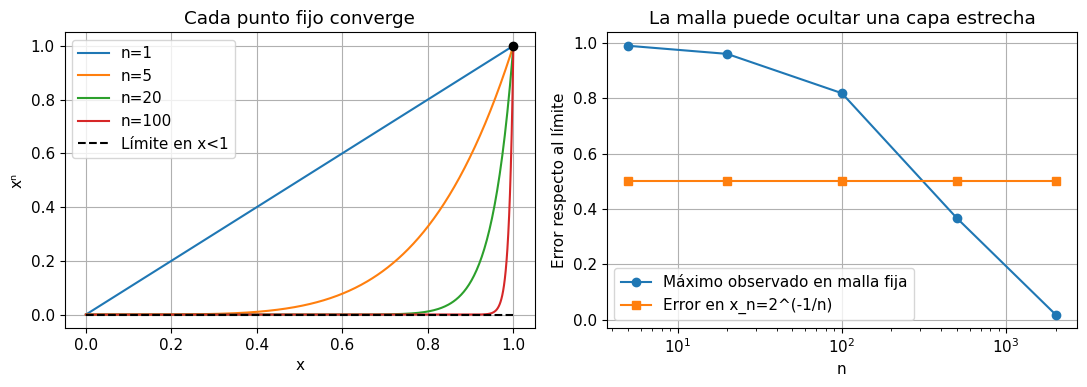

In [3]:
x = np.linspace(0, 1, 501)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n in [1, 5, 20, 100]:
    axes[0].plot(x, x**n, label=f"n={n}")
axes[0].plot([0, 1], [0, 0], "k--", label="Límite en x<1")
axes[0].plot(1, 1, "ko")
axes[0].set(xlabel="x", ylabel="xⁿ", title="Cada punto fijo converge"); axes[0].legend()
ns = np.array([5, 20, 100, 500, 2000])
# En una malla fija el máximo para x<1 puede engañar al crecer n.
error_malla = np.array([np.max(x[:-1]**n) for n in ns])
error_adaptado = (2**(-1/ns))**ns
axes[1].semilogx(ns, error_malla, "o-", label="Máximo observado en malla fija")
axes[1].semilogx(ns, error_adaptado, "s-", label="Error en x_n=2^(-1/n)")
axes[1].set(xlabel="n", ylabel="Error respecto al límite", title="La malla puede ocultar una capa estrecha")
axes[1].legend(); plt.tight_layout(); plt.show()

## 7. Por qué un gráfico puede dar una conclusión falsa

La malla fija no sigue la región cada vez más estrecha cerca de uno. El máximo verdadero para $x<1$ es un supremo igual a uno, aunque ningún punto del intervalo abierto lo alcance. El valor $1/2$ en $x_n$ demuestra de manera exacta que el error no tiende uniformemente a cero.

Este fenómeno aparece en capas límite de PDEs o modelos que ajustan bien sensores pero fallan entre ellos. Una evaluación densa mejora evidencia, pero una cota o un análisis de regularidad aporta algo diferente.

## 8. Series de funciones y criterio de Weierstrass

Si $|g_n(x)|\le M_n$ para todos los $x$ y $\sum_n M_n<\infty$, la serie $\sum_ng_n(x)$ converge uniformemente. Es el criterio $M$ de Weierstrass: la cola queda acotada por una serie numérica independiente de $x$.

Para $e^x=\sum_{j=0}^\infty x^j/j!$ en $[0,1]$, cada término está acotado por $1/j!$. El resto de Taylor satisface $|R_N(x)|\le e/(N+1)!$. Esta cota uniforme justifica aproximar toda la función en ese dominio, no solo un punto.

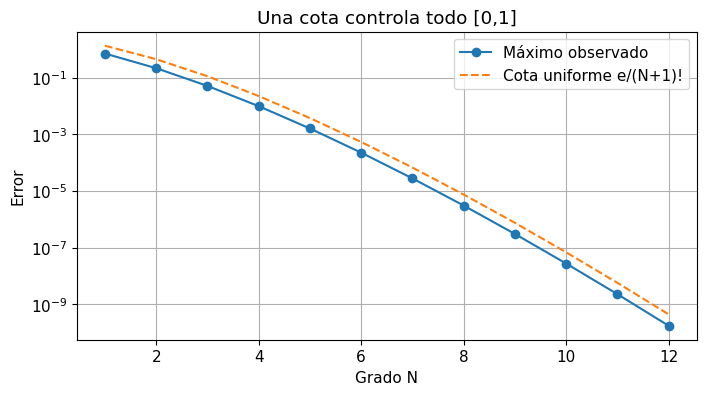

In [4]:
import math
x = np.linspace(0, 1, 500)
Ns = np.arange(1, 13)
err_taylor, cota_taylor = [], []
for N in Ns:
    approx = sum(x**j/math.factorial(j) for j in range(int(N)+1))
    err_taylor.append(np.max(np.abs(approx-np.exp(x))))
    cota_taylor.append(np.e/math.factorial(int(N)+1))
fig, ax = plt.subplots()
ax.semilogy(Ns, err_taylor, "o-", label="Máximo observado")
ax.semilogy(Ns, cota_taylor, "--", label="Cota uniforme e/(N+1)!")
ax.set(xlabel="Grado N", ylabel="Error", title="Una cota controla todo [0,1]")
ax.legend(); plt.show()

## 9. Converger en valores no implica converger en derivadas

$f_n(x)=\sin(nx)/n$ converge uniformemente a cero porque $|f_n|\le1/n$. Pero $f_n'(x)=\cos(nx)$ no converge a la derivada de cero; en $x=0$ siempre vale uno.

Por eso no basta con que una red aproxime valores de una solución si necesitamos gradientes, flujo o residual de una PDE. El espacio y la norma de aproximación deben corresponder a la cantidad requerida. Teoremas de diferenciación de límites exigen condiciones adicionales, como control apropiado de derivadas.

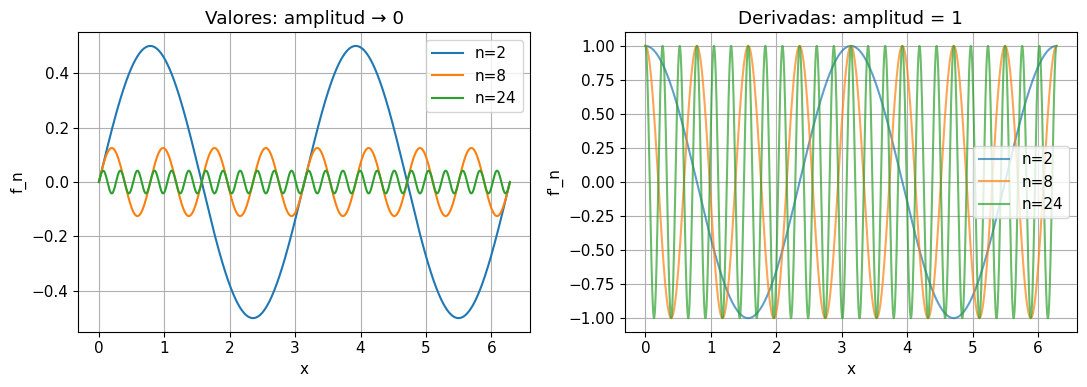

In [5]:
x = np.linspace(0, 2*np.pi, 2000)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n in [2, 8, 24]:
    axes[0].plot(x, np.sin(n*x)/n, label=f"n={n}")
    axes[1].plot(x, np.cos(n*x), alpha=0.7, label=f"n={n}")
axes[0].set(xlabel="x", ylabel="f_n", title="Valores: amplitud → 0")
axes[1].set(xlabel="x", ylabel="f'_n", title="Derivadas: amplitud = 1")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 10. Integrales e intercambio de límites

Convergencia uniforme sobre un intervalo finito permite pasar el límite dentro de la integral, pues
$$\left|\int_a^b(f_n-f)\,dx\right|\le(b-a)\|f_n-f\|_\infty.$$
Pero uniformidad no es necesaria: $x^n\to0$ casi en todas partes en $[0,1]$ y $\int_0^1x^n\,dx=1/(n+1)\to0$. El teorema de convergencia dominada permite el intercambio si $|f_n|\le g$ para una función integrable independiente de $n$ y hay convergencia casi en todas partes.

Sin ese control, consideremos $s_n(x)=n\mathbf1_{(0,1/n)}(x)$. Converge puntualmente a cero en $[0,1]$, pero su integral siempre es uno. La masa se concentra en una región que se estrecha; no existe una dominación integrable común que permita aplicar el teorema.

n=5: integral numérica de pico=0.99900, exacta=1
n=20: integral numérica de pico=0.99600, exacta=1
n=80: integral numérica de pico=0.99200, exacta=1


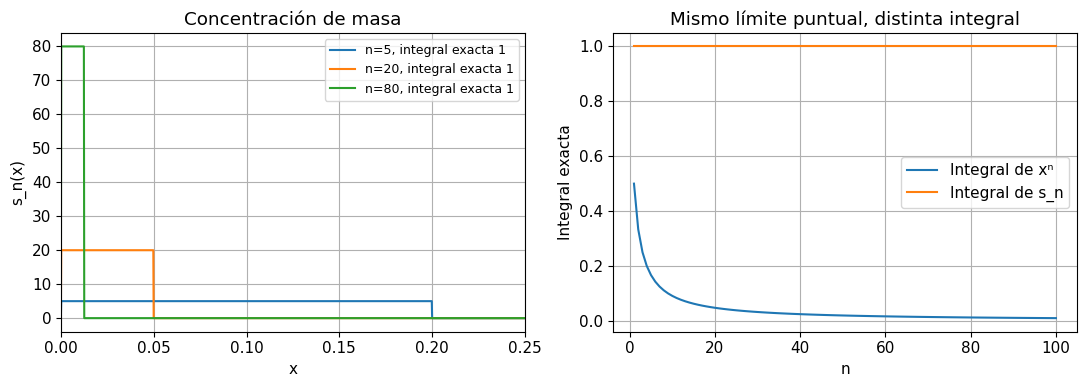

In [6]:
x = np.linspace(0, 1, 5001)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n in [5, 20, 80]:
    spike = n*((x > 0)&(x < 1/n))
    axes[0].plot(x, spike, label=f"n={n}, integral exacta 1")
    print(f"n={n}: integral numérica de pico={trapezoid(spike, x):.5f}, exacta=1")
axes[0].set(xlim=(0, 0.25), xlabel="x", ylabel="s_n(x)", title="Concentración de masa"); axes[0].legend(fontsize=9)
ns = np.arange(1, 101)
axes[1].plot(ns, 1/(ns+1), label="Integral de xⁿ")
axes[1].plot(ns, np.ones_like(ns), label="Integral de s_n")
axes[1].set(xlabel="n", ylabel="Integral exacta", title="Mismo límite puntual, distinta integral")
axes[1].legend(); plt.tight_layout(); plt.show()

## 11. Contracciones y punto fijo

Sea $T$ una aplicación de un espacio métrico completo en sí mismo con $d(Tx,Ty)\le q d(x,y)$ y $q<1$. El teorema de Banach garantiza un único punto fijo y convergencia de $x_{n+1}=T(x_n)$. Una cota es
$$|x_n-x_*|\le\frac{q^n}{1-q}|x_1-x_0|.$$
Para $T(x)=\cos x$ en $[0,1]$, la imagen está dentro de $[0,1]$ y $|T'(x)|\le\sin1<1$. El intervalo cerrado es completo, así que las hipótesis están claras.

La demostración usa que diferencias sucesivas decrecen geométricamente, haciendo a la sucesión de Cauchy. Completitud da un límite; continuidad de $T$ da el punto fijo; la contracción da unicidad. Este mecanismo aparece en existencia de ODEs mediante iteración de Picard.

Punto fijo: 0.7390851332151559


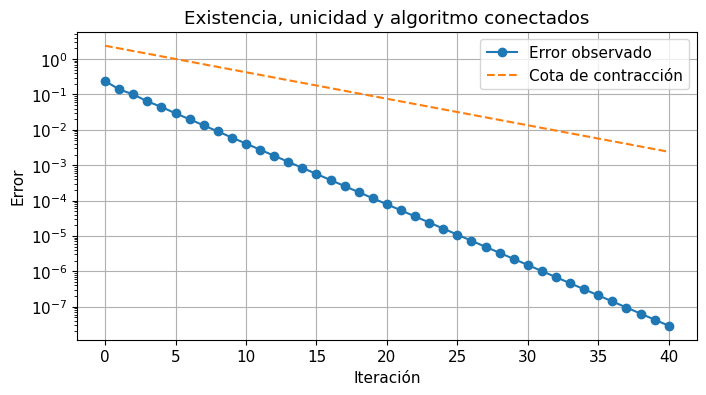

In [7]:
q = np.sin(1.0)
valores = [0.5]
for _ in range(40): valores.append(np.cos(valores[-1]))
valores = np.array(valores)
referencia = brentq(lambda z: z-np.cos(z), 0, 1)
indices = np.arange(len(valores))
cota = q**indices/(1-q)*abs(valores[1]-valores[0])
fig, ax = plt.subplots()
ax.semilogy(indices, np.maximum(abs(valores-referencia), 1e-16), "o-", label="Error observado")
ax.semilogy(indices, cota, "--", label="Cota de contracción")
ax.set(xlabel="Iteración", ylabel="Error", title="Existencia, unicidad y algoritmo conectados")
ax.legend(); plt.show()
print("Punto fijo:", referencia)

## 12. Medida, casi en todas partes y funciones equivalentes

La integral de Lebesgue permite trabajar con funciones poco regulares y con conjuntos de medida cero. «Casi en todas partes» significa salvo un conjunto de medida cero. Cambiar una función en un punto no modifica una norma $L^p$ finita ni su integral, pero sí puede modificar un valor puntual.

Esta distinción será central en análisis funcional: una solución débil se interpreta mediante integrales y clases de equivalencia. No siempre tiene sentido pedir una derivada clásica o un valor en cada punto. La regularidad adicional determina qué cantidades puntuales pueden evaluarse.

## 13. Conexión con SciML y límites de la evidencia

Las convergencias de valores, derivadas y residuos son preguntas distintas. Una pérdida finita evalúa una colección de puntos, no una norma continua exacta. La aproximación de operadores requiere definir sobre qué clase de entradas y en qué topología se controla el error.

Las demostraciones de este cuaderno aportan ejemplos de condiciones suficientes y contraejemplos. Python ilustra esos comportamientos; no prueba automáticamente teoremas generales. Al leer «converge», identifica objeto, dominio, norma y orden de cuantificadores.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../20_INVESTIGACION/20_3_Diseño_experimental.ipynb) | [⏩](../21_MATEMATICA_MAS_AVANZADA/21_2_Analisis_funcional.ipynb) |